In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas_market_calendars as mcal
import statsmodels.api as sm
from sklearn.preprocessing import StandardScaler

# Read data
original_data = pd.read_csv("conglomerated-updated-policy.csv")
price_data = pd.read_csv("index-prices.csv")
volume_data = pd.read_csv("index-options-vol-nse-only.csv")
turnover_data = pd.read_csv("index-turnover-nse-only.csv")

Index(['Date', 'BANKNIFTY', 'FINNIFTY', 'MIDCPNIFTY', 'NIFTY', 'NIFTYNXT50'], dtype='object')

In [ ]:
# Set event date (make timezone-aware to match trading_days)
event_date = pd.Timestamp("2025-07-03", tz='UTC')

# Load official NSE trading calendar
nse = mcal.get_calendar("NSE")    

# Create a schedule for the year around event
schedule = nse.schedule(start_date="2024-12-01", end_date="2025-07-03")

# Extract the valid trading days as a DatetimeIndex
days = mcal.date_range(schedule, frequency="1D")

# Find the index of the event date (or nearest previous trading day if not found)
if event_date in days:
    event_idx = days.get_loc(event_date)
else:
    # If event_date not a trading day, use previous trading day
    event_idx = days.get_indexer([event_date], method='ffill')[0]
    event_date = days[event_idx]

# Go back 120 trading days
start_idx = max(event_idx - 120, 0)
start_date = days[start_idx]

print("120 trading days before:", start_date.date())


Event date (trading day): 2025-07-02
120 trading days before: 2025-01-15


In [ ]:
# Filter original_data based on date cutoffs
original_data['Date'] = pd.to_datetime(original_data['Date'])
cutoff_date = pd.to_datetime('2025-07-02')
data = original_data[original_data['Date'] <= cutoff_date]
cutoff_date_before = pd.to_datetime('2025-01-15')
data = original_data[original_data['Date'] >= cutoff_date_before]

In [ ]:
# Calculate total Client OI (sum of all client positions)
data['Client_Total_OI'] = (
    data['Client_Future Index Long'] + data['Client_Future Index Short'] +
    data['Client_Option Index Call Long'] + data['Client_Option Index Put Long'] +
    data['Client_Option Index Call Short'] + data['Client_Option Index Put Short']
)

# Y1: Retail Share
data['Retail_Share'] = (data['Client_Total_OI'] / data['Total_OI']) * 100

# Y2: Retail Short Ratio
data['Client_Short_OI'] = (
    data['Client_Future Index Short'] +
    data['Client_Option Index Call Short'] +
    data['Client_Option Index Put Short']
)
data['Retail_Short_Ratio'] = data['Client_Short_OI'] / data['Client_Total_OI']

# Y3: Retail Put Share
data['Client_Put_OI'] = data['Client_Option Index Put Long'] + data['Client_Option Index Put Short']
data['Client_Call_OI'] = data['Client_Option Index Call Long'] + data['Client_Option Index Call Short']
data['Retail_Put_Share'] = data['Client_Put_OI'] / (data['Client_Put_OI'] + data['Client_Call_OI'])

regression_data = pd.concat([X, data[['Retail_Share', 'Retail_Short_Ratio', 'Retail_Put_Share']]], axis=1)
regression_data = regression_data.dropna()

In [ ]:
# Calculate turnover-weighted market returns across indices with same date cutoffs as `data`

# Ensure date columns have consistent datetime types
price_data['Date'] = pd.to_datetime(price_data['Date'])
turnover_data['Date'] = pd.to_datetime(turnover_data['Date'])

# Set index names for consistency
indices = ['BANKNIFTY', 'FINNIFTY', 'MIDCPNIFTY', 'NIFTY', 'NIFTYNXT50']

# Calculate log returns for each index
returns_df = price_data[['Date'] + indices].sort_values('Date').copy()
for idx in indices:
    returns_df[f'{idx}_Return'] = np.log(returns_df[idx] / returns_df[idx].shift(1))

# Calculate weights based on turnover
turnover_df = turnover_data[['Date'] + indices].sort_values('Date').copy()
for idx in indices:
    turnover_df[f'{idx}_Weight'] = turnover_df[idx] / turnover_df[indices].sum(axis=1)

# Merge returns and weights on Date
merged = pd.merge(returns_df[['Date'] + [f'{idx}_Return' for idx in indices]],
                  turnover_df[['Date'] + [f'{idx}_Weight' for idx in indices]],
                  on='Date', how='inner')

# Calculate weighted market return
def weighted_return(row):
    return sum(row[f'{idx}_Return'] * row[f'{idx}_Weight'] for idx in indices)

merged['Weighted_Market_Return'] = merged.apply(weighted_return, axis=1)

# Reorder columns for clarity
output_cols = ['Date']
for idx in indices:
    output_cols.append(f'{idx}_Return')
for idx in indices:
    output_cols.append(f'{idx}_Weight')
output_cols.append('Weighted_Market_Return')

final_df = merged[output_cols].sort_values('Date').reset_index(drop=True)

# Handle missing values by dropping rows with any NaNs
final_df = final_df.dropna().reset_index(drop=True)

# Restrict dates to the same as in `data` df
min_date, max_date = data['Date'].min(), data['Date'].max()
final_df = final_df[(final_df['Date'] >= min_date) & (final_df['Date'] <= max_date)].reset_index(drop=True)

final_df.head()

,Date,BANKNIFTY_Return,FINNIFTY_Return,MIDCPNIFTY_Return,NIFTY_Return,NIFTYNXT50_Return,BANKNIFTY_Weight,FINNIFTY_Weight,MIDCPNIFTY_Weight,NIFTY_Weight,NIFTYNXT50_Weight,Weighted_Market_Return
0,2025-01-15,0.000463,-0.001852,0.004137,0.001602,0.008766,0.077346,0.138544,0.287464,0.292828,0.203818,0.003224
1,2025-01-16,0.010752,0.011558,0.010791,0.004239,0.014430,0.100029,0.108007,0.241634,0.384815,0.165516,0.008951
2,2025-01-17,-0.015091,-0.014733,0.002271,-0.004669,0.007547,0.115281,0.150333,0.215726,0.361606,0.157054,-0.003968
3,2025-01-20,0.016553,0.013989,0.009088,0.006082,0.000807,0.133305,0.131822,0.252966,0.346368,0.135539,0.008566
4,2025-01-21,-0.015929,-0.016616,-0.023339,-0.013807,-0.026458,0.104230,0.145468,0.226321,0.341319,0.182663,-0.018905


In [ ]:
volume_data['Date'] = pd.to_datetime(volume_data['Date'])
indices = ['BANKNIFTY', 'FINNIFTY', 'NIFTY', 'NIFTYNXT50']

# Calculate daily sum across specified indices
volume_data['Total_Volume'] = volume_data[indices].sum(axis=1, skipna=True)

# Filter by date cutoffs from `data`
min_date, max_date = data['Date'].min(), data['Date'].max()
filtered_vol = volume_data[(volume_data['Date'] >= min_date) & (volume_data['Date'] <= max_date)].copy()
filtered_vol = filtered_vol[['Date'] + indices + ['Total_Volume']].sort_values('Date').reset_index(drop=True)

filtered_vol.head()

,Date,BANKNIFTY,FINNIFTY,NIFTY,NIFTYNXT50,Total_Volume
0,2025-01-15,15219707.0,513341.0,102419069.0,1770.0,118153887.0
1,2025-01-16,16603299.0,619514.0,176205834.0,2286.0,193430933.0
2,2025-01-17,20621956.0,571998.0,52401536.0,2765.0,73598255.0
3,2025-01-20,22167848.0,743840.0,48421798.0,4820.0,71338306.0
4,2025-01-21,23274674.0,683070.0,86518028.0,3171.0,110478943.0


In [ ]:
# Create a dataframe for regression: Yt = α + β1(WeightedMarketReturn) + β2(IndiaVIX) + β3(isExpiryt) + β4(Liquidity) + ε

# Merge on Date to get all needed columns:
regressors_df = final_df[['Date', 'Weighted_Market_Return']].copy()
regressors_df = regressors_df.merge(
    data[['Date', 'NSE VIX - India', 'is_expiry']],
    on='Date',
    how='inner')
regressors_df = regressors_df.merge(
    filtered_vol[['Date', 'Total_Volume']],
    on='Date',
    how='inner')

# Rename columns for modeling clarity
regressors_df = regressors_df.rename(columns={
    'Weighted_Market_Return': 'WeightedMarketReturn',
    'NSE VIX - India': 'IndiaVIX',
    'is_expiry': 'isExpiry',
    'Total_Volume': 'Liquidity'
})

# Final output: Date plus all model X variables
regressors_df = regressors_df[['Date', 'WeightedMarketReturn', 'IndiaVIX', 'isExpiry', 'Liquidity']].sort_values('Date').reset_index(drop=True)
regressors_df.head()

,Date,WeightedMarketReturn,IndiaVIX,isExpiry,Liquidity
0,2025-01-15,0.003224,14.9150,0,118153887.0
1,2025-01-16,0.008951,15.9975,0,193430933.0
2,2025-01-17,-0.003968,15.4700,0,73598255.0
3,2025-01-20,0.008566,15.2575,0,71338306.0
4,2025-01-21,-0.018905,15.4650,0,110478943.0


In [ ]:
# Merge Retail_Share based on Date
regression_df = regressors_df.copy().merge(
    data[['Date', 'Retail_Share', 'Retail_Put_Share', 'Retail_Short_Ratio']], on='Date', how='inner'
)

# Drop rows with NaNs (any variable, dependent or independent)
regression_df_clean = regression_df.dropna().reset_index(drop=True)

# Standardize continuous regressors (exclude dummies)
scaler = StandardScaler()
continuous_cols = ['WeightedMarketReturn', 'IndiaVIX', 'Liquidity']
regression_df_clean[continuous_cols] = scaler.fit_transform(regression_df_clean[continuous_cols])

# Prepare regression variables
X = regression_df_clean[['WeightedMarketReturn', 'IndiaVIX', 'isExpiry', 'Liquidity']]
X = sm.add_constant(X)

# Run OLS regression
Y1 = regression_df_clean['Retail_Share']
model = sm.OLS(Y1, X).fit(cov_type='HAC', cov_kwds={'maxlags':5})
print(model.summary())


                            OLS Regression Results                            
Dep. Variable:           Retail_Share   R-squared:                       0.363
Model:                            OLS   Adj. R-squared:                  0.349
Method:                 Least Squares   F-statistic:                     18.22
Date:                Wed, 26 Nov 2025   Prob (F-statistic):           1.20e-12
Time:                        00:44:46   Log-Likelihood:                -409.24
No. Observations:                 191   AIC:                             828.5
Df Residuals:                     186   BIC:                             844.7
Df Model:                           4                                         
Covariance Type:                  HAC                                         
                           coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------
const                   59.4923 

In [58]:
Y2 = regression_df_clean['Retail_Short_Ratio']
model2 = sm.OLS(Y2, X).fit(cov_type='HAC', cov_kwds={'maxlags':5})
print(model2.summary())

                            OLS Regression Results                            
Dep. Variable:     Retail_Short_Ratio   R-squared:                       0.024
Model:                            OLS   Adj. R-squared:                  0.003
Method:                 Least Squares   F-statistic:                     1.871
Date:                Wed, 26 Nov 2025   Prob (F-statistic):              0.117
Time:                        00:44:46   Log-Likelihood:                 582.79
No. Observations:                 191   AIC:                            -1156.
Df Residuals:                     186   BIC:                            -1139.
Df Model:                           4                                         
Covariance Type:                  HAC                                         
                           coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------
const                    0.5188 

In [59]:
Y3 = regression_df_clean['Retail_Put_Share']
model3 = sm.OLS(Y3, X).fit(cov_type='HAC', cov_kwds={'maxlags':5})
print(model3.summary())

                            OLS Regression Results                            
Dep. Variable:       Retail_Put_Share   R-squared:                       0.441
Model:                            OLS   Adj. R-squared:                  0.429
Method:                 Least Squares   F-statistic:                     24.70
Date:                Wed, 26 Nov 2025   Prob (F-statistic):           2.06e-16
Time:                        00:44:46   Log-Likelihood:                 359.16
No. Observations:                 191   AIC:                            -708.3
Df Residuals:                     186   BIC:                            -692.1
Df Model:                           4                                         
Covariance Type:                  HAC                                         
                           coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------
const                    0.4686 

### Event Study for Retail_Share: +10 Day Post-Event Window

,Retail_Share,Abnormal,CAR
Date,,,
2025-07-03,60.475015,2.461790,2.461790
2025-07-04,62.960838,4.947613,7.409404
2025-07-07,62.905948,4.892723,12.302127
2025-07-08,62.605511,4.592286,16.894413
2025-07-09,61.647833,3.634608,20.529021
2025-07-10,60.294908,2.281683,22.810704
2025-07-11,60.802154,2.788929,25.599634
2025-07-14,61.276931,3.263707,28.863340
2025-07-15,62.863836,4.850612,33.713952


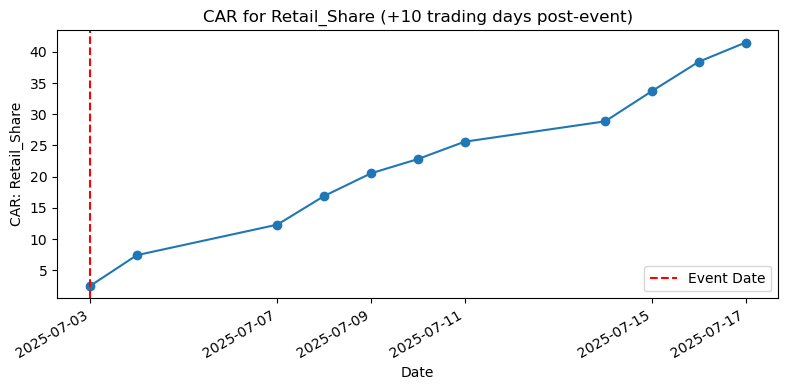

Summary statistics for +10 day window post-event for Retail_Share (n=11):
        Retail_Share   Abnormal        CAR
count     11.000000  11.000000  11.000000
mean      61.785972   3.772747  22.772993
std        1.048868   1.048868  12.482349
min       60.294908   2.281683   2.461790
25%       60.948644   2.935419  14.598270
50%       61.647833   3.634608  22.810704
75%       62.790710   4.777486  31.288646
max       62.960838   4.947613  41.500221


### Event Study for Retail_Put_Share: +10 Day Post-Event Window

,Retail_Put_Share,Abnormal,CAR
Date,,,
2025-07-03,0.477693,0.009584,0.009584
2025-07-04,0.467037,-0.001072,0.008512
2025-07-07,0.468926,0.000816,0.009328
2025-07-08,0.495386,0.027277,0.036605
2025-07-09,0.453963,-0.014147,0.022458
2025-07-10,0.469135,0.001025,0.023484
2025-07-11,0.413456,-0.054654,-0.031170
2025-07-14,0.406757,-0.061352,-0.092523
2025-07-15,0.454978,-0.013132,-0.105655


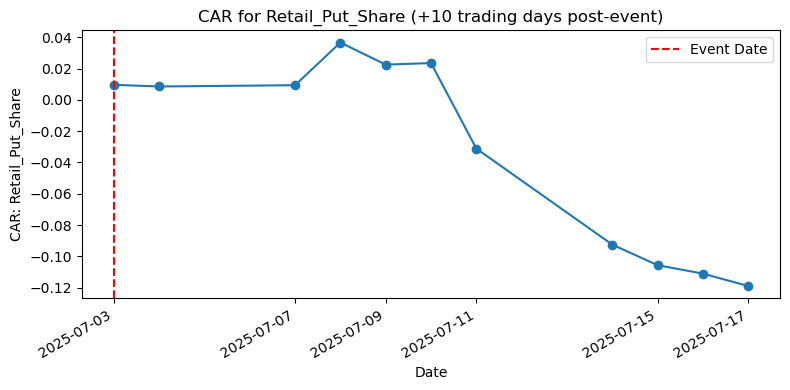

Summary statistics for +10 day window post-event for Retail_Put_Share (n=11):
        Retail_Put_Share   Abnormal        CAR
count         11.000000  11.000000  11.000000
mean           0.457294  -0.010816  -0.031762
std            0.026015   0.026015   0.062231
min            0.406757  -0.061352  -0.118973
25%            0.454470  -0.013639  -0.099089
50%            0.462732  -0.005378   0.008512
75%            0.469030   0.000921   0.016021
max            0.495386   0.027277   0.036605


### Event Study for Retail_Short_Ratio: +10 Day Post-Event Window

,Retail_Short_Ratio,Abnormal,CAR
Date,,,
2025-07-03,0.530148,0.011040,0.011040
2025-07-04,0.536881,0.017773,0.028813
2025-07-07,0.528355,0.009247,0.038060
2025-07-08,0.523009,0.003900,0.041960
2025-07-09,0.517730,-0.001378,0.040582
2025-07-10,0.522477,0.003369,0.043951
2025-07-11,0.521401,0.002293,0.046243
2025-07-14,0.521635,0.002527,0.048770
2025-07-15,0.518515,-0.000593,0.048177


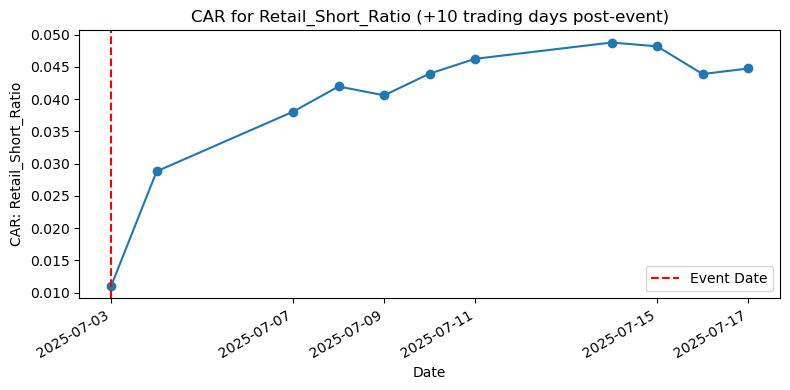

Summary statistics for +10 day window post-event for Retail_Short_Ratio (n=11):
        Retail_Short_Ratio   Abnormal        CAR
count           11.000000  11.000000  11.000000
mean             0.523176   0.004068   0.039657
std              0.006332   0.006332   0.010984
min              0.514816  -0.004292   0.011040
25%              0.519241   0.000133   0.039321
50%              0.521635   0.002527   0.043885
75%              0.525682   0.006574   0.045494
max              0.536881   0.017773   0.048770


In [65]:
# Event study for July 3 SEBI order: single +10 trading day post-event window
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display, Markdown

event_date = pd.to_datetime('2025-07-03')
estimation_window = 120  # trading days before event for baseline mean
post_event_window = 10   # trading days after event

retail_metrics = ['Retail_Share', 'Retail_Put_Share', 'Retail_Short_Ratio']

for y in retail_metrics:
    # Create series with Date as index, sorted
    series = data[['Date', y]].set_index('Date').sort_index()
    # Find trading day anchor for event
    if event_date in series.index:
        event_idx = series.index.get_loc(event_date)
        anchor_event_date = event_date
    else:
        # Anchor to previous trading day if event date not in data
        event_idx = series.index.searchsorted(event_date, side='right') - 1
        anchor_event_date = series.index[event_idx]
    # Select estimation window (trading days)
    start_idx = max(event_idx - estimation_window, 0)
    est_data = series.iloc[start_idx:event_idx][y]
    mu_hat = est_data.mean()
    display(Markdown(f"### Event Study for {y}: +10 Day Post-Event Window"))
    # Select +10 trading days post event
    end = min(event_idx + post_event_window, len(series) - 1)
    window_data = series.iloc[event_idx:end+1][y]
    event_df = window_data.to_frame()
    event_df['Abnormal'] = event_df[y] - mu_hat
    event_df['CAR'] = event_df['Abnormal'].cumsum()
    display(event_df)
    # Plot CAR for +10 days
    plt.figure(figsize=(8, 4))
    plt.plot(event_df.index, event_df['CAR'], marker='o')
    plt.axvline(anchor_event_date, color='red', linestyle='--', label='Event Date')
    plt.title(f'CAR for {y} (+10 trading days post-event)')
    plt.xlabel('Date')
    plt.ylabel(f'CAR: {y}')
    plt.legend()
    # Rotate and space x-ticks for readability
    ticks = event_df.index[::2]  # show every other date
    plt.xticks(ticks, [str(i.date()) for i in ticks], rotation=30, ha='right')
    plt.tight_layout()
    plt.show()
    print(f"Summary statistics for +10 day window post-event for {y} (n={len(event_df)}):\n", event_df.describe())
